# Saudi Used-Car Price Prediction — 3rd place solution

**Competition:** *How Much Is Your Car Worth?* (Elm Student Club, in-person Kaggle competition, 4 hours)
**Task:** predict the listing price (SAR) of a used car in Saudi Arabia · **Metric:** RMSLE (lower is better)

This notebook walks through the full solution:

1. The data and its traps (Hijri years, Arabic digits, mixed-language cities, hidden nulls, placeholder prices, duplicates)
2. Cleaning and feature engineering (code lives in [`src/features.py`](../src/features.py))
3. A 2-level stacking ensemble — LightGBM, XGBoost, CatBoost and an MLP, blended by a Ridge meta-model (code in [`src/train.py`](../src/train.py))
4. Results and the submission file

> The competition data is not included in this repository. See the README for how to download it into `data/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from features import (preprocess, clean_train_rows, build_features,
                      hijri_to_gregorian_year, clean_mileage, extract_trim_from_title)
from train import run_stacking, rmsle_log, MODELS

DATA_DIR = ROOT / "data"
ASSETS = ROOT / "assets"
ASSETS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train_df.shape, "| test:", test_df.shape)
train_df.head()

train: (10550, 14) | test: (5000, 13)


,id,brand,model,model_year,mileage,transmission,trim,specs,city,seller_type,listing_date,color,title,price
0,104747,Toyota,Fortuner,2025,22000,Automatic,Standard,GCC,Jeddah,Individual,2025-08-14,Red,فورتشنر 2025 ستاندر مستخدم شخصي,146000
1,111023,Dodge,Charger,2019,70000 km,Automatic,Standard,Saudi,Riyadh,Dealer,2025-02-27,Grey,Charger 2019 for sale,76500
2,103201,Ford,Taurus,2026,13000,Automatic,Semi Full,Saudi,Makkah,Individual,2026-03-31,White,Taurus semi full minor accident,168500
3,109402,Honda,Accord,2023,45000,Automatic,Full Option,Saudi,Riyadh,Dealer,2025-09-05,Silver,Accord damaged,104000
4,109277,Geely,Emgrand,2021,266000,-,Semi Full,Saudi,Buraydah,Individual,2025-08-16,غير محدد,امجراند 2021 نص فل نظيف,20000


## 1. The data and its traps

The dataset is semi-synthetic and deliberately messy, like real listings on Saudi marketplaces.
Most of the score came from cleaning these issues correctly, not from model tuning.

In [2]:
mileage_str = train_df["mileage"].astype(str)
checks = {
    "Model year written in Hijri (< 1900)": (train_df["model_year"] < 1900).sum(),
    "Mileage with text / Arabic digits / commas": mileage_str.str.contains(r"[^0-9]").sum(),
    "Placeholder price (0 or 1 SAR)": train_df["price"].isin([0, 1]).sum(),
    "Distinct raw city spellings": train_df["city"].nunique(),
    "Hidden nulls ('-' or 'غير محدد') in categoricals": int(
        train_df[["transmission", "trim", "specs", "seller_type", "color"]]
        .isin(["-", "غير محدد"]).sum().sum()),
    "Missing trim": train_df["trim"].isna().sum(),
}
pd.Series(checks, name="rows in train").to_frame()

,rows in train
Model year written in Hijri (< 1900),548
Mileage with text / Arabic digits / commas,1503
Placeholder price (0 or 1 SAR),250
Distinct raw city spellings,46
Hidden nulls ('-' or 'غير محدد') in categoricals,1044
Missing trim,215


In [3]:
# Examples of what the raw columns look like
examples = pd.DataFrame({
    "raw mileage": mileage_str[mileage_str.str.contains(r"[^0-9]")].head(6).values,
    "raw city": train_df["city"].drop_duplicates().sample(6, random_state=1).values,
    "raw title": train_df["title"].sample(6, random_state=3).values,
})
examples

,raw mileage,raw city,raw title
0,70000 km,أبها,التيما عادي نظيف جداً
1,"63,000",tabuk,كورولا نظيف بسعر مغري
2,"51,000",Makkah,التيما 2020 عادي نظيف
3,٢٠٠٠,مكة,فوكس 2010 فل كامل حادث بسيط
4,"83,000",Buraydah,يارس حادث بسيط للبيع
5,176645 km,Jeddah,صني ستاندر


In [4]:
hijri = train_df.loc[train_df["model_year"] < 1900, "model_year"].drop_duplicates().sort_values().head(8)
pd.DataFrame({"hijri year": hijri.values,
              "-> gregorian": hijri_to_gregorian_year(hijri).values})

,hijri year,-> gregorian
0,1429,2008
1,1430,2009
2,1431,2010
3,1432,2011
4,1433,2012
5,1434,2013
6,1435,2014
7,1436,2015


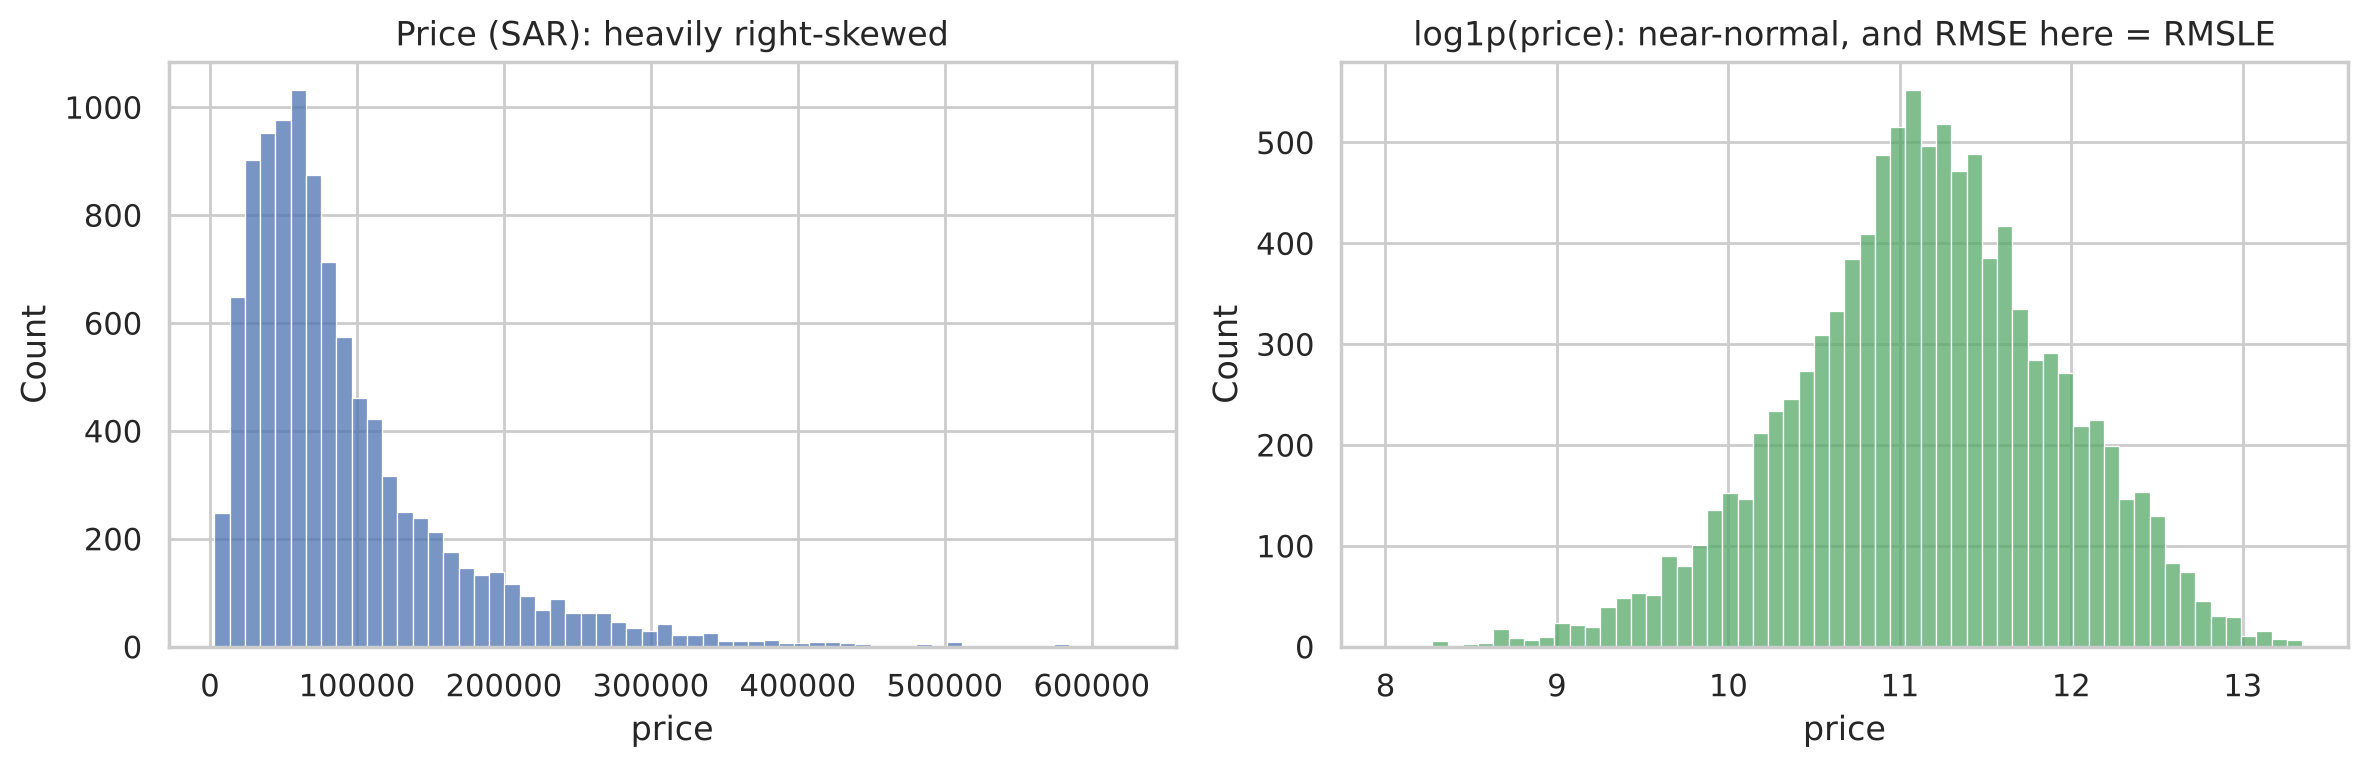

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
p = train_df.loc[train_df["price"] > 1, "price"]
sns.histplot(p, bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Price (SAR): heavily right-skewed")
sns.histplot(np.log1p(p), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("log1p(price): near-normal, and RMSE here = RMSLE")
plt.tight_layout(); plt.savefig(ASSETS / "target_distribution.png", dpi=120); plt.show()

**Why train on `log1p(price)`?** RMSLE is exactly the RMSE of `log1p(y)`. Training every model on the
log target optimises the competition metric directly and stops expensive cars from dominating the loss.

## 2. Cleaning and feature engineering

`preprocess()` is purely row-wise, so it is applied to train and test independently (no leakage).
The only learned statistic, median mileage per car age, is fitted on train only.

| Step | What it does |
|---|---|
| Hidden nulls | `-` and `غير محدد` ("not specified") → NaN → own `Unknown` level |
| Hijri → Gregorian | `year * 0.970224 + 621.57` for years < 1900 |
| Mileage | Arabic-Indic digits → Latin, strip `km` / commas → int |
| City | 40+ Arabic/English spellings → 10 canonical cities |
| Age | `exact_age` from listing date (fractional years), `car_age` |
| Usage | `log_mileage`, `km_per_year`, mileage relative to median for that age |
| Title NLP | Regex flags for damaged / minor accident / very clean / excellent → `condition_score`; recover missing `trim` from title (Arabic + English keywords) |
| Domain | `brand_model` combo, `is_luxury`, ordinal `trim` |
| Rows | Drop placeholder prices (0/1 SAR) and duplicate re-posted listings |

In [6]:
X, y, X_test = build_features(train_df, test_df)
print("X:", X.shape, "| X_test:", X_test.shape)
print("Remaining nulls -> train:", int(X.isna().sum().sum()), "| test:", int(X_test.isna().sum().sum()))
print("Cities after cleaning:", sorted(X["city"].cat.categories))

X: (10000, 28) | X_test: (5000, 28)
Remaining nulls -> train: 0 | test: 0
Cities after cleaning: ['Abha', 'Buraydah', 'Dammam', 'Hail', 'Jeddah', 'Khobar', 'Madinah', 'Makkah', 'Riyadh', 'Tabuk']


In [7]:
# How well does the title-based trim extractor work? Check it on rows where trim IS known.
known = train_df[train_df["trim"].notna() & ~train_df["trim"].isin(["-", "غير محدد"])]
pred = known["title"].apply(extract_trim_from_title)
mask = pred.notna()
print(f"Title mentions a trim in {mask.mean():.1%} of rows; "
      f"when it does, it matches the true trim {(pred[mask] == known.loc[mask, 'trim']).mean():.1%} of the time.")

Title mentions a trim in 60.2% of rows; when it does, it matches the true trim 99.3% of the time.


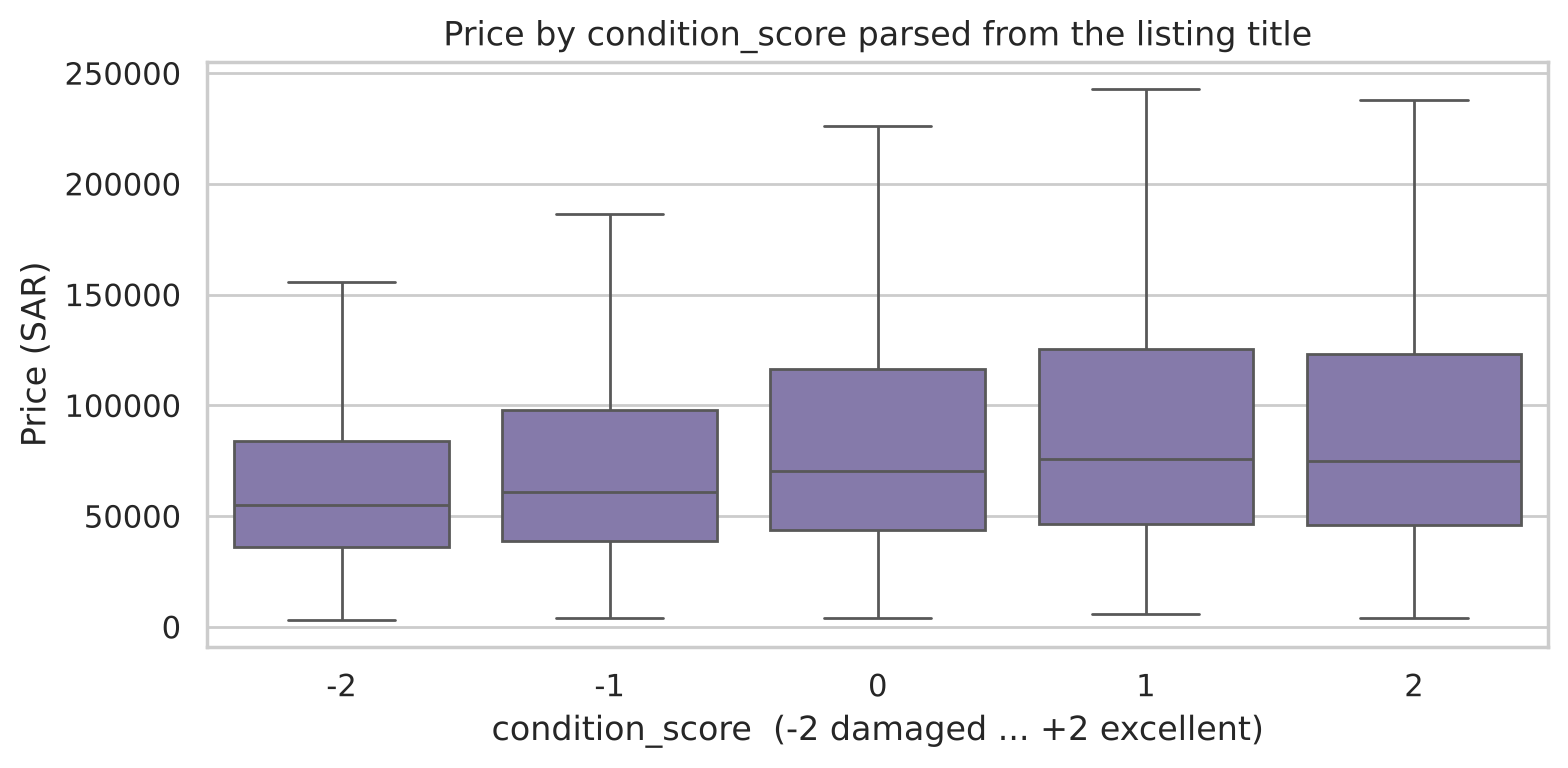

In [8]:
# Condition parsed from the title vs price
tmp = X.assign(price=y.values)
order = sorted(tmp["condition_score"].unique())
plt.figure(figsize=(8, 4))
sns.boxplot(data=tmp, x="condition_score", y="price", order=order, showfliers=False, color="#8172B2")
plt.title("Price by condition_score parsed from the listing title")
plt.xlabel("condition_score  (-2 damaged ... +2 excellent)"); plt.ylabel("Price (SAR)")
plt.tight_layout(); plt.savefig(ASSETS / "condition_vs_price.png", dpi=120); plt.show()

## 3. Model: 2-level stacking

```
                 ┌──────────── 5-fold KFold on log1p(price) ────────────┐
 features ──►    │  LightGBM   XGBoost   CatBoost   MLP (scaled + OHE)  │
                 └──────┬─────────┬─────────┬──────────┬────────────────┘
                        └── out-of-fold predictions (4 columns) ──┐
                                                                  ▼
                                               RidgeCV meta-model (level 2)
                                                                  ▼
                                                    expm1 → price (SAR)
```

* **Level 1:** each model is trained 5 times (one per fold). Predictions on the held-out fold form an
  out-of-fold (OOF) matrix that no model has seen during training; test predictions are averaged over folds.
* **Level 2:** a Ridge regression on the 4 OOF columns learns how much to trust each model.
  Ridge's L2 penalty keeps the weights stable when the base models are highly correlated.
* Categoricals are handled natively by LightGBM, XGBoost and CatBoost (CatBoost uses ordered target
  statistics); the MLP gets a standard-scaled + one-hot pipeline fitted inside each fold.

Runtime: about 2–3 minutes on a 4-core CPU.

In [9]:
res = run_stacking(X, y, X_test, n_splits=5)

Fold 1/5: LGB 0.1149 | XGB 0.1163 | CAT 0.1143 | MLP 0.1521


Fold 2/5: LGB 0.1147 | XGB 0.1167 | CAT 0.1150 | MLP 0.1526


Fold 3/5: LGB 0.1141 | XGB 0.1148 | CAT 0.1126 | MLP 0.1509


Fold 4/5: LGB 0.1173 | XGB 0.1188 | CAT 0.1180 | MLP 0.1823


Fold 5/5: LGB 0.1166 | XGB 0.1186 | CAT 0.1148 | MLP 0.1542

OOF RMSLE per model:
  LGB  0.11551
  XGB  0.11703
  CAT  0.11496
  MLP  0.15886
  STACK 0.11233
Meta weights (LGB, XGB, CAT, MLP): [0.312 0.174 0.47  0.049]


In [10]:
y_log = res["y_log"]
scores = pd.DataFrame({
    "model": [m.upper() for m in MODELS] + ["STACK (Ridge)"],
    "OOF RMSLE": [rmsle_log(y_log, res["oof"][m]) for m in MODELS] + [rmsle_log(y_log, res["oof_stack"])],
    "meta weight": list(np.round(res["meta"].coef_, 3)) + [np.nan],
}).round(5)
scores

,model,OOF RMSLE,meta weight
0,LGB,0.11551,0.312
1,XGB,0.11703,0.174
2,CAT,0.11496,0.470
3,MLP,0.15886,0.049
4,STACK (Ridge),0.11233,NaN


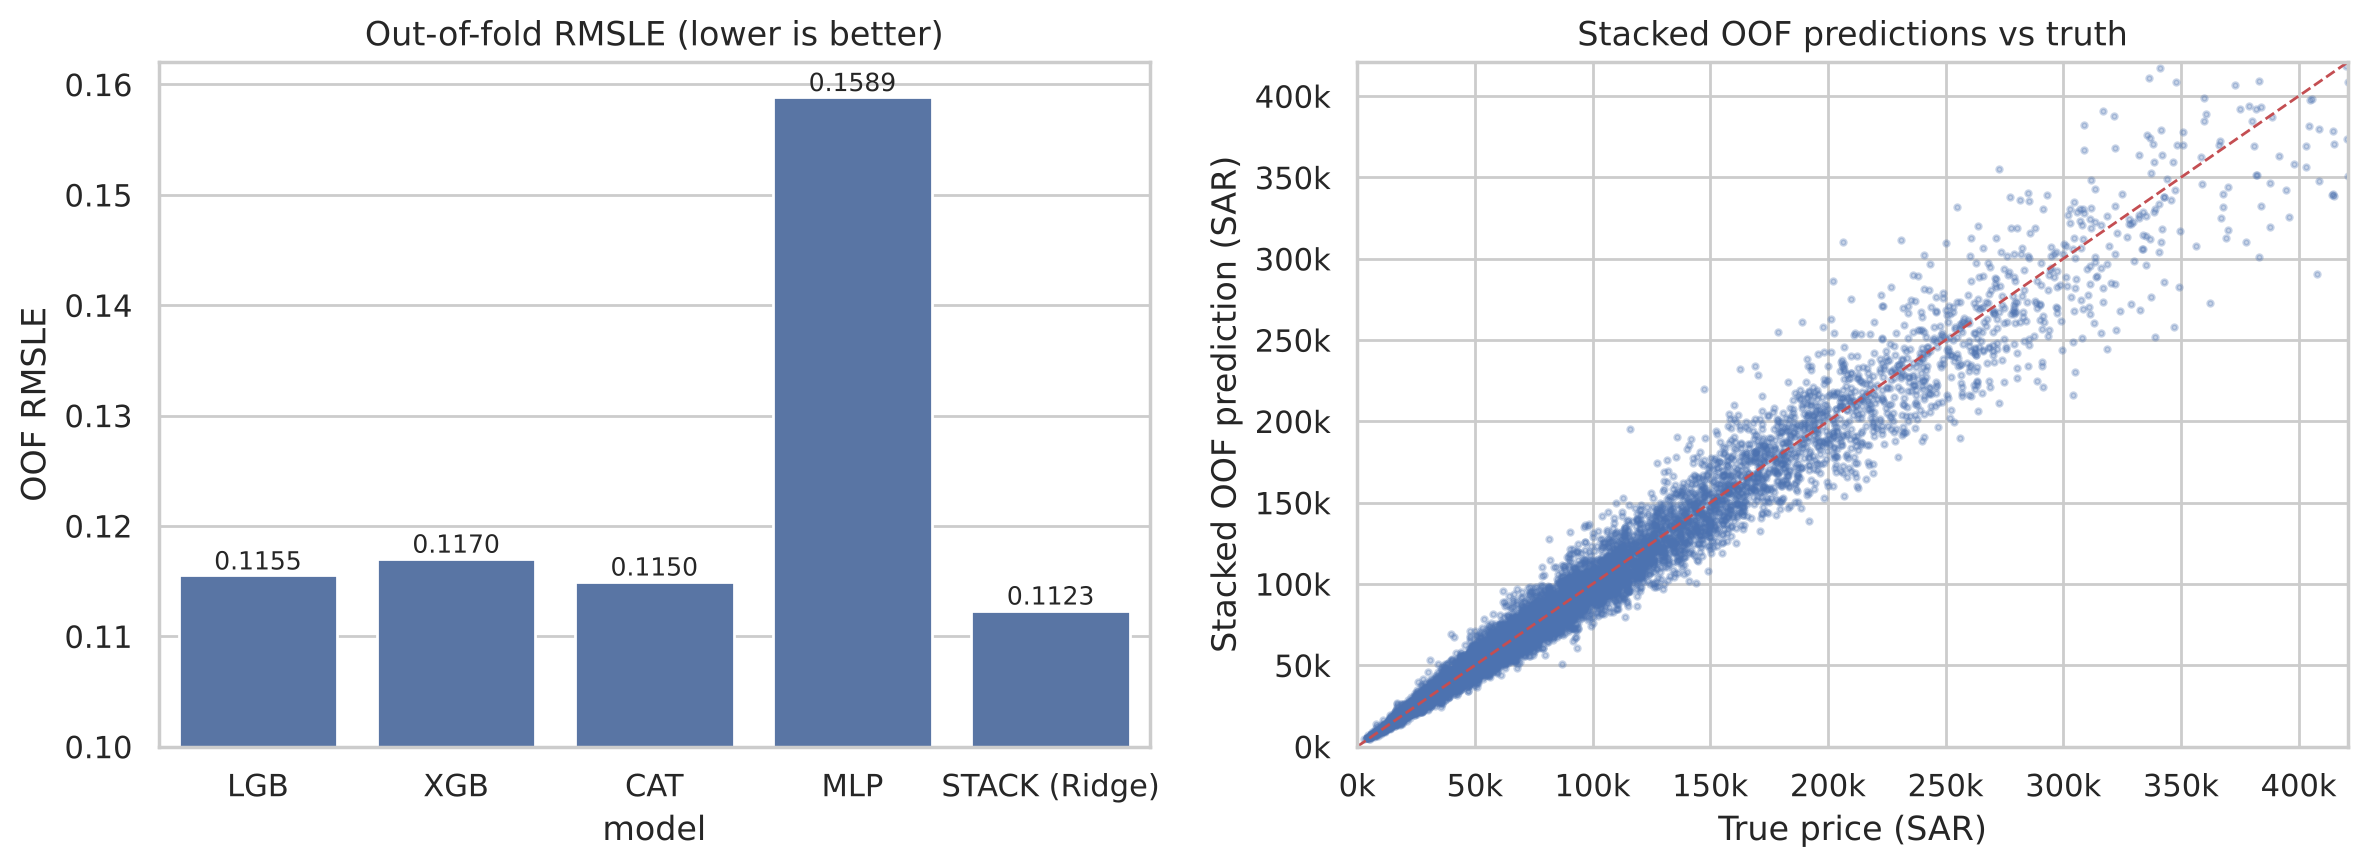

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=scores, x="model", y="OOF RMSLE", ax=axes[0], color="#4C72B0")
axes[0].set_ylim(0.10, scores["OOF RMSLE"].max() * 1.02); axes[0].set_title("Out-of-fold RMSLE (lower is better)")
for i, v in enumerate(scores["OOF RMSLE"]):
    axes[0].text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
axes[1].scatter(np.expm1(y_log), np.expm1(res["oof_stack"]), s=4, alpha=0.3)
lim = [0, np.percentile(np.expm1(y_log), 99.5)]
axes[1].plot(lim, lim, "r--", lw=1); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
fmt = plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k")
axes[1].xaxis.set_major_formatter(fmt); axes[1].yaxis.set_major_formatter(fmt)
axes[1].set_xlabel("True price (SAR)"); axes[1].set_ylabel("Stacked OOF prediction (SAR)")
axes[1].set_title("Stacked OOF predictions vs truth")
plt.tight_layout(); plt.savefig(ASSETS / "results.png", dpi=120); plt.show()

## 4. Submission

In [12]:
submission = pd.DataFrame({"id": test_df["id"].values,
                           "price": np.clip(np.expm1(res["test_stack"]), 0, None)})
out = ROOT / "submissions" / "submission.csv"
out.parent.mkdir(exist_ok=True)
submission.to_csv(out, index=False)
print("Saved", out.relative_to(ROOT), submission.shape)
submission.head()

Saved submissions/submission.csv (5000, 2)


,id,price
0,105612,91776.398473
1,113899,37490.869289
2,105778,114924.674343
3,107846,25246.580727
4,102948,163942.042033


## 5. What I would try next

* **Repeated / multi-seed CV** for the base models (cheap variance reduction).
* **Target encoding of `brand_model`** fitted out-of-fold, plus group stats such as price-per-age within each model.
* **Stronger text features** from the title (TF-IDF char n-grams → linear model as a 5th base model).
* **Adversarial validation** between train and test to catch distribution shift before it hits the private leaderboard.